# 07 - Réseau de neurones pour la classification

Jusqu'ici on prédisait un **nombre** (régression). On transforme maintenant le problème en **classification** :
prédire le **niveau de demande** de la journée.

| | Régression | Classification multi-classe | Classification binaire |
|---|---|---|---|
| Sortie | `Dense(1)` linéaire | `Dense(k, activation="softmax")` | `Dense(1, activation="sigmoid")` |
| Perte | MAE / MSE | `sparse_categorical_crossentropy` | `binary_crossentropy` |
| Métrique | MAE | accuracy | accuracy, AUC |

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from velo_utils import load_splits, plot_history, PALETTE

keras.utils.set_random_seed(42)  # reproductibilité
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [2]:
X_train, X_test, y_train, y_test = load_splits()
Xtr, Xte = X_train.to_numpy(), X_test.to_numpy()
ytr, yte = y_train.to_numpy(), y_test.to_numpy()
n_features = Xtr.shape[1]
print("train :", Xtr.shape, "| test :", Xte.shape)

train : (585, 33) | test : (146, 33)


## 1. Création des classes

On découpe `cnt` en trois classes de même effectif, à partir des **tertiles du train** :

In [3]:
CLASSES = ["faible", "moyenne", "forte"]
q1, q2 = np.quantile(ytr, [1 / 3, 2 / 3])
print(f"faible < {q1 * 1000:.0f} locations <= moyenne < {q2 * 1000:.0f} locations <= forte")

def to_class(y):
    return np.digitize(y, [q1, q2])  # 0, 1 ou 2

ctr, cte = to_class(ytr), to_class(yte)
print("effectifs train :", dict(zip(CLASSES, np.bincount(ctr))))
print("effectifs test  :", dict(zip(CLASSES, np.bincount(cte))))

faible < 3746 locations <= moyenne < 5307 locations <= forte
effectifs train : {'faible': np.int64(195), 'moyenne': np.int64(195), 'forte': np.int64(195)}
effectifs test  : {'faible': np.int64(50), 'moyenne': np.int64(46), 'forte': np.int64(50)}


## 2. Le réseau

Même structure que pour la régression ; seule la couche de sortie change : **3 neurones + softmax**,
qui donnent une probabilité par classe (leur somme vaut 1).

In [4]:
def make_classifier(n_classes=3):
    norm = layers.Normalization()
    norm.adapt(Xtr)
    model = keras.Sequential([
        keras.Input(shape=(n_features,)),
        norm,
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(n_classes, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

clf = make_classifier()
clf.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 33)             │            67 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,598 (25.78 KB)

 Trainable params: 6,531 (25.51 KB)

 Non-trainable params: 67 (272.00 B)

Arrêt à l'époque 34


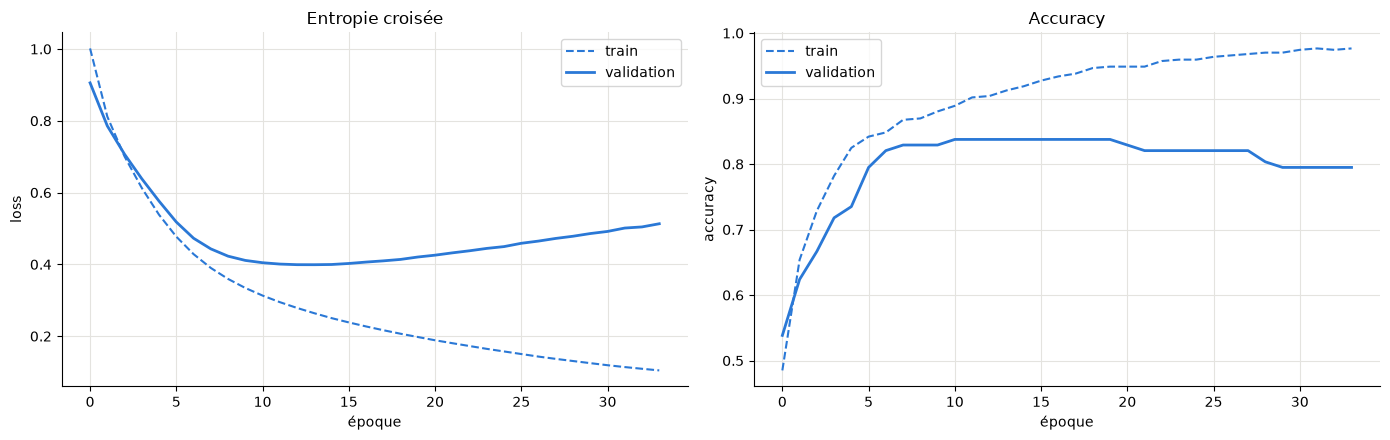

In [5]:
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
h_clf = clf.fit(Xtr, ctr, epochs=200, batch_size=32, validation_split=0.2, callbacks=[early], verbose=0)
print("Arrêt à l'époque", len(h_clf.history["loss"]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
plot_history(h_clf, title="Entropie croisée", ylabel="loss", ax=ax1)
plot_history(h_clf, metric="accuracy", title="Accuracy", ylabel="accuracy", ax=ax2)
plt.tight_layout()
plt.show()

## 3. Évaluation

In [6]:
test_loss, test_acc = clf.evaluate(Xte, cte, verbose=0)
baseline = np.mean(cte == np.bincount(ctr).argmax())
print(f"Accuracy test : {test_acc:.3f}  (référence « classe majoritaire » : {baseline:.3f})")

Accuracy test : 0.808  (référence « classe majoritaire » : 0.342)


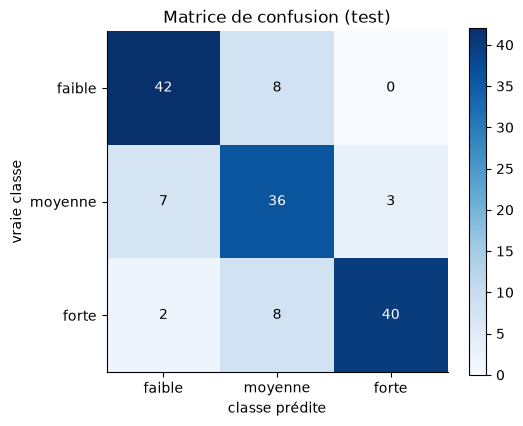

In [7]:
proba = clf.predict(Xte, verbose=0)
c_pred = proba.argmax(axis=1)
cm = tf.math.confusion_matrix(cte, c_pred, num_classes=3).numpy()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), CLASSES)
ax.set_yticks(range(3), CLASSES)
ax.grid(False)
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set(xlabel="classe prédite", ylabel="vraie classe", title="Matrice de confusion (test)")
fig.colorbar(im, ax=ax)
plt.show()

Les erreurs se font presque toujours entre classes **voisines** (faible ↔ moyenne, moyenne ↔ forte) :
le réseau a bien compris l'ordre des niveaux même si on ne le lui a pas donné.

La sortie softmax donne aussi la **confiance** du modèle :

In [8]:
from velo_utils import load_raw

raw = load_raw()
pos = np.sort(np.random.default_rng(1).choice(len(X_test), size=10, replace=False))  # 10 jours au hasard
sample = X_test.index[pos]
pd.DataFrame({
    "date": raw.loc[sample, "dteday"].dt.date.values,
    "locations": raw.loc[sample, "cnt"].values,
    "vraie classe": [CLASSES[c] for c in cte[pos]],
    "prédite": [CLASSES[c] for c in c_pred[pos]],
    **{f"P({c})": proba[pos, i].round(2) for i, c in enumerate(CLASSES)},
})

,date,locations,vraie classe,prédite,P(faible),P(moyenne),P(forte)
0,2011-01-29,1098,faible,faible,0.99,0.01,0.00
1,2011-03-29,2425,faible,faible,0.86,0.14,0.00
2,2011-06-01,3974,moyenne,moyenne,0.00,0.97,0.03
3,2011-07-17,5302,moyenne,moyenne,0.32,0.64,0.04
4,2011-10-19,2424,faible,faible,0.99,0.01,0.00
5,2011-11-18,3392,faible,faible,0.52,0.47,0.00
6,2012-06-21,5905,forte,forte,0.00,0.07,0.93
7,2012-08-12,6544,forte,forte,0.00,0.10,0.90
8,2012-11-08,5315,forte,forte,0.27,0.34,0.39
9,2012-11-16,5698,forte,moyenne,0.02,0.66,0.32


## 4. Classification binaire : journée de forte affluence ?

On veut maintenant savoir si la journée dépassera **5 000 locations**. Une seule sortie avec une **sigmoïde**
donne la probabilité de la classe positive.

Part de journées >= 5000 : train 0.40, test 0.37


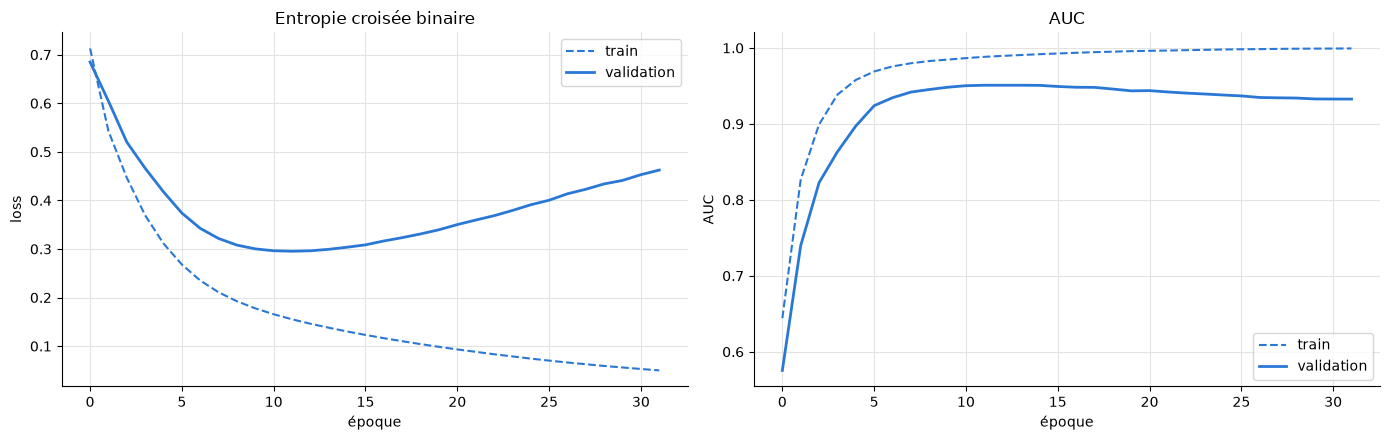

Test : accuracy = 0.932, AUC = 0.959


In [9]:
SEUIL = 5.0  # milliers de locations
btr, bte = (ytr >= SEUIL).astype("float32"), (yte >= SEUIL).astype("float32")
print(f"Part de journées >= {SEUIL * 1000:.0f} : train {btr.mean():.2f}, test {bte.mean():.2f}")

norm = layers.Normalization()
norm.adapt(Xtr)
bin_clf = keras.Sequential([
    keras.Input(shape=(n_features,)),
    norm,
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
bin_clf.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                loss="binary_crossentropy",
                metrics=["accuracy", keras.metrics.AUC(name="auc")])
h_bin = bin_clf.fit(Xtr, btr, epochs=200, batch_size=32, validation_split=0.2,
                    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)],
                    verbose=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
plot_history(h_bin, title="Entropie croisée binaire", ylabel="loss", ax=ax1)
plot_history(h_bin, metric="auc", title="AUC", ylabel="AUC", ax=ax2)
plt.tight_layout()
plt.show()

loss, acc, auc = bin_clf.evaluate(Xte, bte, verbose=0)
print(f"Test : accuracy = {acc:.3f}, AUC = {auc:.3f}")

Par défaut on prédit « forte affluence » si la probabilité dépasse 0.5. Ce **seuil de décision** est un choix :
le baisser détecte plus de journées chargées, au prix de plus de fausses alertes.

In [10]:
p = bin_clf.predict(Xte, verbose=0).flatten()
rows = []
for s in [0.2, 0.35, 0.5, 0.65, 0.8]:
    pred = p >= s
    tp = np.sum(pred & (bte == 1))
    rows.append({
        "seuil": s,
        "accuracy": np.mean(pred == bte),
        "précision": tp / max(pred.sum(), 1),
        "rappel": tp / bte.sum(),
    })
pd.DataFrame(rows).set_index("seuil").round(3)

,accuracy,précision,rappel
seuil,,,
0.20,0.890,0.817,0.907
0.35,0.911,0.887,0.870
0.50,0.932,0.940,0.870
0.65,0.890,0.932,0.759
0.80,0.863,0.972,0.648


## À vous de jouer

- Passez à 5 classes (quintiles) : l'accuracy baisse-t-elle ? Les erreurs restent-elles entre classes voisines ?
- Comparez avec la régression du notebook 02 : convertissez ses prédictions en classes avec `to_class` et calculez son accuracy.
- Changez le seuil de 5 000 locations (3 000, 7 000) : que deviennent l'accuracy et l'AUC quand les classes sont déséquilibrées ?